# 📈 Pronóstico del IPAP-BMC · Reto B
**BMC DataLab Challenge · Índice de Precios Agropecuarios de la Bolsa Mercantil de Colombia, Total agropecuario (mensual)**

**Objetivo.** Pronosticar el IPAP-BMC a 12 meses, incluido **octubre de 2026**, y medir su precisión con una **prueba histórica** sobre los últimos 12 meses observados (MAPE).

**Modelo final.** Promedio simple de cuatro componentes:
**ARIMA(1,1,0) con deriva + Estacional + Telaraña con índice de transacciones BMC + Bottom-up sectorial.**
Se compara contra un **modelo ingenuo** (línea base).

| Sección | Contenido | Rúbrica |
|---|---|---|
| 1–4 | Configuración, datos BMC y exploración | B1 · Uso de datos BMC |
| 5 | Diseño de la evaluación y MAPE | B2 |
| 6 | Línea base: modelo ingenuo | B2 |
| 7 | Modelo final: ecuaciones y código | Metodología |
| 8 | **Prueba histórica** (últimos 12 meses) | B2 · Precisión MAPE |
| 9 | Comparación con la línea base y diagnóstico | Robustez |
| 10 | **Pronóstico futuro a 12 meses** | B2 · Claridad del pronóstico |
| 11 | Exportación de resultados | B4 · Reproducibilidad |

**Archivos necesarios (datos BMC):**
1. `Comparativo niveles IPAP por sector.xlsx`: IPAP total y 32 sectores.
2. `Solicitud de información Datalab Challenge - Los Ninis.xlsx`: transacciones (cantidades y valor negociado).

**Cómo ejecutarlo en Google Colab:** arrastra los dos archivos al panel 📁 de la izquierda y usa `Entorno de ejecución → Ejecutar todo` (≈ 2 minutos).

## 1. Configuración

In [1]:
# !pip install -q statsmodels openpyxl      # Colab ya trae pandas, numpy, scipy y matplotlib
import os, glob, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import nnls
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox
from IPython.display import display
warnings.filterwarnings("ignore"); np.random.seed(42)

H            = 12          # meses de prueba histórica y de pronóstico
MES_OBJETIVO = "2026-10"   # mes de la mención especial
MIN_MESES    = 60          # mínimo de observaciones exigido por la rúbrica
LAMBDA       = 1.0         # penalización ridge de la Telaraña
VENTANA_BU   = 60          # meses para estimar los pesos sectoriales
RECORTE      = 0.15        # recorte de cambios mensuales de precios de transacciones
CARPETA      = "outputs"; os.makedirs(f"{CARPETA}/figuras", exist_ok=True)

COL = {"real":"#1F2937","pred":"#2563EB","test":"#F59E0B","banda":"#93C5FD","ing":"#9CA3AF",
       "ARIMA":"#7C3AED","Estacional":"#059669","Telaraña":"#DC2626","Bottom-up":"#0891B2"}
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,
                     "axes.grid":True,"grid.alpha":.25,"font.size":10})

def buscar(patron, descripcion):
    """Busca el archivo en la carpeta de trabajo; si no está, lo pide (Colab)."""
    f = sorted(glob.glob(patron) + glob.glob("/content/" + patron))
    if f: return f[0]
    from google.colab import files
    print(f"👉 Sube: {descripcion}"); return next(iter(files.upload()))
print("Configuración lista ✔")

Configuración lista ✔


## 2. Datos BMC · IPAP total y sectores
El archivo trae tres columnas: **fecha**, **sector** y **valor del índice**. `Total agropecuario` es la serie que se pronostica; los 32 sectores alimentan el componente *Bottom-up*.

In [2]:
f_ipap = buscar("*niveles*IPAP*.xlsx", "Comparativo niveles IPAP por sector.xlsx")
raw = pd.read_excel(f_ipap, header=None, usecols=[0, 1, 2]); raw.columns = ["fecha", "sector", "valor"]
raw["fecha"]  = pd.to_datetime(raw["fecha"], errors="coerce"); raw = raw.dropna(subset=["fecha"])
raw["sector"] = raw["sector"].astype(str).str.strip()
raw["valor"]  = pd.to_numeric(raw["valor"], errors="coerce")

panel = raw.pivot_table(index="fecha", columns="sector", values="valor"); panel.index = panel.index.to_period("M")
y = panel["Total agropecuario"].dropna()                                   # IPAP total
S = panel.drop(columns="Total agropecuario").loc[y.index]; S = S.loc[:, S.notna().all()]   # sectores
assert len(y) >= MIN_MESES + H, f"Se requieren al menos {MIN_MESES + H} meses"
print(f"IPAP total: {y.index[0]} a {y.index[-1]} ({len(y)} meses) · sectores: {S.shape[1]}")

👉 Sube: Comparativo niveles IPAP por sector.xlsx


Saving Comparativo niveles IPAP por sector.xlsx to Comparativo niveles IPAP por sector.xlsx
IPAP total: 2012-01 a 2026-07 (175 meses) · sectores: 32


## 3. Datos BMC · Transacciones → índice mediano de precios
Las transacciones traen, por producto y mes, la **cantidad** negociada $Q_{i,t}$ y el **valor negociado** $V_{i,t}$.

**Paso 1 · Precio implícito** de cada producto $i$:
$$p_{i,t}=\frac{V_{i,t}}{Q_{i,t}}$$

**Paso 2 · Cambio de precio de cada categoría $c$** (índice Törnqvist): promedio de los cambios logarítmicos de sus productos, ponderado por el valor negociado promedio de los dos meses:
$$\Delta\ln P_{c,t}=\sum_{i\in c}\bar\omega_{i,t}\,\Delta\ln p_{i,t},\qquad \bar\omega_{i,t}=\frac{V_{i,t}+V_{i,t-1}}{\sum_{k\in c}\left(V_{k,t}+V_{k,t-1}\right)}$$

**Paso 3 · Índice mediano** de las 12 categorías, con cambios recortados a ±15 % (los saltos mayores suelen venir de cambios en la mezcla de productos, no del precio):
$$m_t=\operatorname{mediana}_{c}\Big(\max\big(-0{,}15,\;\min(0{,}15,\;\Delta\ln P_{c,t})\big)\Big)$$

*Regla de no fuga de información:* solo se usan transacciones hasta el último mes con IPAP publicado.

In [3]:
f_tr = buscar("*Solicitud*.xlsx", "Solicitud de información Datalab Challenge - Los Ninis.xlsx")
d = pd.read_excel(f_tr); d = d[pd.to_numeric(d["Año"], errors="coerce").notna()].copy()
MES = {m: i + 1 for i, m in enumerate(["enero","febrero","marzo","abril","mayo","junio","julio",
                                         "agosto","septiembre","octubre","noviembre","diciembre"])}
d["P"] = pd.PeriodIndex.from_fields(year=d["Año"].astype(int), month=d["Mes"].str.strip().str.lower().map(MES), freq="M")
d = d[(d["Cantidades"] > 0) & (d["valor_negocio"] > 0) & (d["Categoría"] != "Abono organico")]  # abono orgánico: solo 4 años

# Paso 1: precio implícito por producto y mes
g = d.groupby(["P","Categoría","Subya característica"], as_index=False)[["Cantidades","valor_negocio"]].sum()
g["precio"] = g["valor_negocio"] / g["Cantidades"]
meses_tr = pd.period_range(g["P"].min(), g["P"].max(), freq="M")

# Paso 2: índice Törnqvist por categoría
cambio_cat = {}
for c, gc in g.groupby("Categoría"):
    lp = np.log(gc.pivot(index="P", columns="Subya característica", values="precio").reindex(meses_tr))
    v  = gc.pivot(index="P", columns="Subya característica", values="valor_negocio").reindex(meses_tr)
    dl = lp.diff(); w = ((v + v.shift(1)) / 2).where(dl.notna())
    cambio_cat[c] = (dl * w).sum(1) / w.sum(1).replace(0, np.nan)
CAT = pd.DataFrame(cambio_cat)

# Paso 3: índice mediano (hasta el último mes del IPAP)
def indice_mediano(recorte=RECORTE):
    return CAT.clip(-recorte, recorte).median(1).loc[:y.index[-1]]
m_tr = indice_mediano()
print(f"Transacciones: {meses_tr[0]} a {meses_tr[-1]} · usadas hasta {m_tr.index[-1]} · categorías: {CAT.shape[1]}")

👉 Sube: Solicitud de información Datalab Challenge - Los Ninis.xlsx


Saving Solicitud de información Datalab Challenge - Los Ninis.xlsx to Solicitud de información Datalab Challenge - Los Ninis.xlsx
Transacciones: 2014-01 a 2026-09 · usadas hasta 2026-07 · categorías: 12


## 4. Exploración de los datos

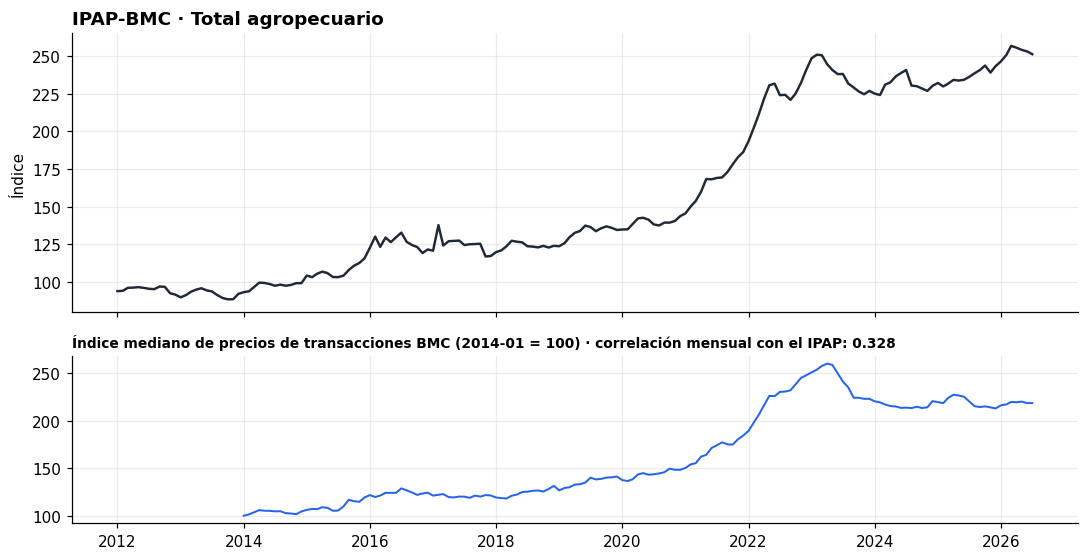

Correlación entre los cambios mensuales del IPAP y del índice mediano: 0.328


In [4]:
dly  = np.log(y).diff()
corr = round(dly.corr(m_tr.reindex(dly.index)), 3)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True, gridspec_kw={"height_ratios": [2, 1.2]})
a1.plot(y.index.to_timestamp(), y.values, color=COL["real"], lw=1.6)
a1.set_title("IPAP-BMC · Total agropecuario", loc="left", fontweight="bold"); a1.set_ylabel("Índice")
idx = 100 * np.exp(m_tr.fillna(0).cumsum())
a2.plot(idx.index.to_timestamp(), idx.values, color=COL["pred"], lw=1.3)
a2.set_title(f"Índice mediano de precios de transacciones BMC (2014-01 = 100) · correlación mensual con el IPAP: {corr}",
             loc="left", fontsize=9, fontweight="bold")
plt.tight_layout(); plt.savefig(f"{CARPETA}/figuras/fig1_datos.png", dpi=200); plt.show()
print(f"Correlación entre los cambios mensuales del IPAP y del índice mediano: {corr}")

## 5. Diseño de la evaluación
```
|◄──────────── Entrenamiento (≥ 60 meses) ────────────►|◄── Prueba histórica: últimos 12 meses ──►|
 primer mes                                             T                                         último mes
```
- El modelo se entrena **solo** con datos hasta $T$ y pronostica los 12 meses siguientes **sin verlos**.
- Después se **reentrena con toda la serie** para el pronóstico futuro.
- Como prueba de estabilidad, el ejercicio se repite en **11 orígenes de validación rodante** anteriores a la prueba (uno cada 6 meses).

**Error porcentual absoluto medio (criterio B2):**
$$\text{MAPE}=\frac{100}{12}\sum_{h=1}^{12}\left|\frac{\text{IPAP}_{T+h}-\widehat{\text{IPAP}}_{T+h}}{\text{IPAP}_{T+h}}\right|$$

| MAPE | 0–5 % | 5–10 % | 10–15 % | 15–20 % | > 20 % |
|---|---|---|---|---|---|
| Nota | **10 · Excelente** | 8 · Bueno | 6 · Aceptable | 4 · Aceptable | 2 · Deficiente |

In [5]:
T = len(y) - H
y_train, y_test = y.iloc[:T], y.iloc[T:]
ORIG_VAL = list(range(T - 72, T - H + 1, 6))          # 11 orígenes de validación rodante

mape = lambda r, p: float(np.mean(np.abs((np.asarray(r) - p) / np.asarray(r))) * 100)
def nota(m): return next((n for l, n in [(5,"10 · Excelente"),(10,"8 · Bueno"),(15,"6 · Aceptable"),(20,"4 · Aceptable")] if m <= l), "2 · Deficiente")
print(f"Entrenamiento: {y_train.index[0]} a {y_train.index[-1]} ({len(y_train)} meses)")
print(f"Prueba:        {y_test.index[0]} a {y_test.index[-1]} ({len(y_test)} meses)")

Entrenamiento: 2012-01 a 2025-07 (163 meses)
Prueba:        2025-08 a 2026-07 (12 meses)


## 6. Línea base: modelo ingenuo
Es el pronóstico más simple posible: **el último valor observado se repite en todos los meses futuros**. Equivale a suponer que el IPAP sigue una caminata aleatoria, es decir, que el mejor pronóstico del próximo mes es el valor de hoy.
$$\widehat{\text{IPAP}}_{T+h}=\text{IPAP}_T,\qquad h=1,\dots,12$$

**¿Para qué sirve?** Es el estándar mínimo en pronóstico de precios: un modelo solo aporta valor si se equivoca **menos** que el ingenuo. Si no lo supera, el modelo no agrega información a la que ya da el último dato publicado.

In [6]:
def m_ingenuo(s, h):
    return np.repeat(s.iloc[-1], h)

## 7. Modelo final
Todos los componentes trabajan sobre el **logaritmo del índice**:
$$\ell_t=\ln(\text{IPAP}_t)\qquad\Rightarrow\qquad \Delta\ell_t=\ell_t-\ell_{t-1}\approx\text{variación porcentual mensual}$$
Así los cambios son porcentuales y el pronóstico, al aplicar $\exp(\cdot)$, nunca es negativo.

$$\boxed{\;\widehat{\text{IPAP}}_{T+h}=\frac{1}{4}\Big(\hat y^{\,\text{ARIMA}}_{T+h}+\hat y^{\,\text{Est}}_{T+h}+\hat y^{\,\text{Tel}}_{T+h}+\hat y^{\,\text{BU}}_{T+h}\Big)\;}$$

### 7.1 ARIMA(1,1,0) con deriva · *tendencia e inercia*
El cambio de este mes depende del cambio del mes anterior más un crecimiento constante:
$$\Delta\ell_t=c+\phi\,\Delta\ell_{t-1}+\varepsilon_t,\qquad \varepsilon_t\sim N(0,\sigma^2)$$
- $c$: deriva (crecimiento mensual de fondo) · $\phi$: persistencia de los cambios ($|\phi|<1$) · se estiman por máxima verosimilitud.

**Pronóstico:** se itera la ecuación con $\varepsilon=0$ y se acumulan los cambios:
$$\widehat{\Delta\ell}_{T+j}=c+\phi\,\widehat{\Delta\ell}_{T+j-1},\qquad \hat y^{\,\text{ARIMA}}_{T+h}=\exp\Big(\ell_T+\sum_{j=1}^{h}\widehat{\Delta\ell}_{T+j}\Big)$$

In [7]:
def m_arima(s, h):
    ajuste = SARIMAX(np.log(s.values), order=(1, 1, 0), trend="c").fit(disp=False)
    return np.exp(ajuste.forecast(h))

### 7.2 Estacional · *patrón típico de cada mes del año*
Las cosechas y la demanda hacen que algunos meses suban o bajen más que el promedio. El efecto del mes $m$ es la diferencia entre su cambio promedio y el cambio promedio de todos los meses:
$$s_m=\frac{1}{N_m}\sum_{t\,:\,\text{mes}(t)=m}\Delta\ell_t-\frac{1}{N}\sum_{t}\Delta\ell_t,\qquad m=1,\dots,12$$
**Pronóstico:** al último dato se le suman los efectos de los meses siguientes:
$$\hat y^{\,\text{Est}}_{T+h}=\text{IPAP}_T\cdot\exp\Big(\sum_{j=1}^{h}s_{\,m(T+j)}\Big)$$
Por construcción $\sum_m s_m\approx0$: este componente no aporta tendencia, solo la forma del año.

In [8]:
def m_estacional(s, h):
    cambios = np.log(s).diff().dropna()
    efecto  = cambios.groupby(cambios.index.month).mean() - cambios.mean()
    meses   = [(s.index[-1] + j).month for j in range(1, h + 1)]
    return s.iloc[-1] * np.exp(np.cumsum([efecto[m] for m in meses]))

### 7.3 Telaraña con índice de transacciones · *ciclo de precios + señal de mercado (modelo propio)*
Se inspira en el **teorema de la telaraña**: cuando los precios agrícolas suben, los productores siembran más; la mayor oferta llega meses después y baja los precios, y viceversa. Para capturar ese ciclo se usan seis variables:
$$z_t=\Big[\;\underbrace{\ell_t-\ell_{t-6}}_{\text{6 meses}},\;\underbrace{\ell_t-\ell_{t-12}}_{\text{12 meses}},\;\underbrace{\ell_{t-12}-\ell_{t-24}}_{\text{año anterior}},\;\underbrace{m_t}_{1\text{ mes}},\;\underbrace{\textstyle\sum_{j=0}^{2}m_{t-j}}_{3\text{ meses}},\;\underbrace{\textstyle\sum_{j=0}^{5}m_{t-j}}_{6\text{ meses}}\;\Big]^{\top}$$
Las tres primeras miden el **momentum del IPAP**; las tres últimas, el cambio acumulado del **índice mediano de transacciones** (sección 3).

**Una regresión por horizonte** (pronóstico directo, $h=1,\dots,12$): explica el cambio del IPAP entre $t$ y $t+h$:
$$\ell_{t+h}-\ell_t=\alpha_h+\beta_h^{\top}\tilde z_t+u_{t,h},\qquad \tilde z_t=\frac{z_t-\bar z}{s_z}\;\text{(variables estandarizadas)}$$
**Estimación ridge:** penaliza coeficientes grandes para evitar sobreajuste con variables correlacionadas ($\lambda=1$):
$$\hat\beta_h=\big(\tilde Z^{\top}\tilde Z+\lambda I\big)^{-1}\tilde Z^{\top}\big(Y_h-\bar Y_h\big),\qquad \hat\alpha_h=\bar Y_h$$
**Pronóstico:**
$$\hat y^{\,\text{Tel}}_{T+h}=\text{IPAP}_T\cdot\exp\big(\hat\alpha_h+\hat\beta_h^{\top}\tilde z_T\big)$$

In [9]:
def variables_telarana(s, tr=None):
    tr = m_tr if tr is None else tr
    l = np.log(s.values); Z = np.full((len(l), 6), np.nan)
    for t in range(24, len(l)):
        Z[t, :3] = [l[t]-l[t-6], l[t]-l[t-12], l[t-12]-l[t-24]]          # momentum del IPAP
    for j, k in enumerate([1, 3, 6]):
        Z[:, 3 + j] = tr.rolling(k).sum().reindex(s.index).values         # índice mediano acumulado
    return Z

def m_telarana(s, h, lam=LAMBDA, tr=None):
    Z = variables_telarana(s, tr); l = np.log(s.values); n = len(l); out = []
    for k in range(1, h + 1):
        r = np.arange(n - k); X, Y = Z[r], l[r + k] - l[r]               # pares (t, t+k) observados
        ok = np.isfinite(X).all(1); X, Y = X[ok], Y[ok]
        mu, sd = X.mean(0), X.std(0); sd[sd == 0] = 1; Xs = (X - mu) / sd
        beta = np.linalg.solve(Xs.T @ Xs + lam * np.eye(6), Xs.T @ (Y - Y.mean()))
        z = np.where(np.isfinite(Z[n-1]), Z[n-1], mu)
        out.append(Y.mean() + ((z - mu) / sd) @ beta)
    return s.iloc[-1] * np.exp(np.array(out))

### 7.4 Bottom-up sectorial · *información de los 32 sectores del IPAP*
El IPAP total resume lo que pasa en sus sectores. Se pronostica cada sector y luego se agregan.

**Paso 1 · Pesos.** Cuánto explica cada sector $j$ de los cambios del total (últimos 60 meses), con mínimos cuadrados **no negativos** (NNLS):
$$\hat w=\arg\min_{w_j\ge0}\;\sum_{t}\Big(\Delta\ell_t-\sum_{j=1}^{32}w_j\,\Delta\ln S_{j,t}\Big)^2$$

**Paso 2 · Pronóstico de cada sector** con suavizamiento exponencial de tendencia amortiguada (ETS), sobre $x_t=\ln S_{j,t}$:
$$a_t=\alpha\,x_t+(1-\alpha)(a_{t-1}+\varphi b_{t-1}),\qquad b_t=\beta\,(a_t-a_{t-1})+(1-\beta)\,\varphi\,b_{t-1}$$
$$\hat x_{T+h}=a_T+(\varphi+\varphi^2+\dots+\varphi^h)\,b_T$$
$a_t$: nivel · $b_t$: tendencia · $\varphi<1$ amortigua la tendencia a largo plazo.

**Paso 3 · Agregación:**
$$\hat y^{\,\text{BU}}_{T+h}=\text{IPAP}_T\cdot\exp\Big(\sum_{j=1}^{32}\hat w_j\,\ln\frac{\hat S_{j,T+h}}{S_{j,T}}\Big)$$

In [10]:
def ets_amortiguado(s, h):
    ajuste = ExponentialSmoothing(np.log(s.values), trend="add", damped_trend=True).fit()
    return np.exp(ajuste.forecast(h))

def m_bottom_up(s, h, ventana=VENTANA_BU):
    sec = S.loc[s.index]
    pesos, _ = nnls(np.diff(np.log(sec.values), axis=0)[-ventana:], np.diff(np.log(s.values))[-ventana:])
    pron_sec = np.column_stack([ets_amortiguado(sec[c], h) for c in sec.columns])
    return s.iloc[-1] * np.exp(np.log(pron_sec / sec.iloc[-1].values) @ pesos)

### 7.5 Combinación · *el modelo final*
$$\widehat{\text{IPAP}}_{T+h}=\frac{1}{4}\Big(\hat y^{\,\text{ARIMA}}_{T+h}+\hat y^{\,\text{Est}}_{T+h}+\hat y^{\,\text{Tel}}_{T+h}+\hat y^{\,\text{BU}}_{T+h}\Big)$$
**¿Por qué un promedio simple?** Cada componente capta un rasgo distinto (tendencia, estacionalidad, ciclo y mercado, sectores), y cuando uno sobreestima otro suele subestimar. Los pesos iguales no se estiman, así que no sobreajustan el pasado.

In [11]:
def modelo_final(s, h, lam=LAMBDA, ventana=VENTANA_BU, tr=None):
    comp = {"ARIMA":      m_arima(s, h),
            "Estacional": m_estacional(s, h),
            "Telaraña":   m_telarana(s, h, lam, tr),
            "Bottom-up":  m_bottom_up(s, h, ventana)}
    comp["MODELO FINAL"] = np.mean([comp[k] for k in ["ARIMA", "Estacional", "Telaraña", "Bottom-up"]], axis=0)
    return comp
print("Modelo final definido ✔")

Modelo final definido ✔


## 8. Prueba histórica (criterio B2)
El modelo se entrena hasta $T$ y pronostica los **últimos 12 meses**, que nunca vio. Esta es la tabla completa que pide la rúbrica.

In [17]:
P_TEST    = modelo_final(y_train, H)
pred_test = P_TEST["MODELO FINAL"]
pred_ing  = m_ingenuo(y_train, H)

tabla_prueba = pd.DataFrame({"Mes": y_test.index.astype(str), "IPAP real": y_test.values.round(2),
                             "IPAP predicho": pred_test.round(2),
                             "Error absoluto (%)": (np.abs(y_test.values - pred_test) / y_test.values * 100).round(2)})
MAPE_FINAL, MAPE_ING = mape(y_test, pred_test), mape(y_test, pred_ing)
display(tabla_prueba)
print(f"\nMAPE prueba histórica · modelo final = {MAPE_FINAL:.2f} % ")
print(f"MAPE prueba histórica · ingenuo      = {MAPE_ING:.2f} %")

,Mes,IPAP real,IPAP predicho,Error absoluto (%)
0,2025-08,238.49,235.23,1.37
1,2025-09,240.65,235.40,2.18
2,2025-10,243.62,235.77,3.22
3,2025-11,238.98,235.89,1.29
4,2025-12,243.25,237.19,2.49
5,2026-01,246.42,239.08,2.98
6,2026-02,250.62,240.92,3.87
7,2026-03,256.72,242.53,5.53
8,2026-04,255.47,244.34,4.36
9,2026-05,254.03,245.05,3.54



MAPE prueba histórica · modelo final = 2.98 % 
MAPE prueba histórica · ingenuo      = 4.62 %


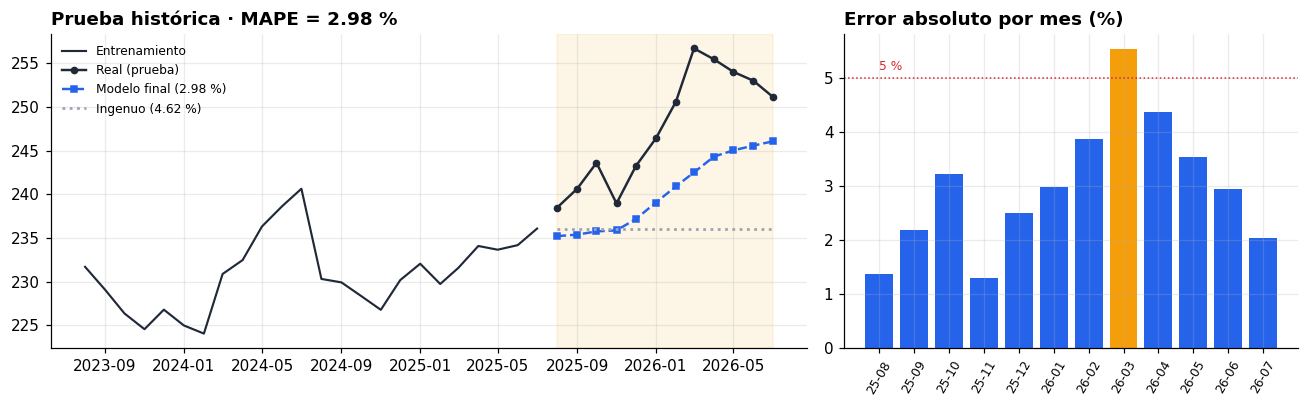

In [13]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2, 1.2]})
f = y_test.index.to_timestamp(); hist = y.iloc[T-24:T]
a1.plot(hist.index.to_timestamp(), hist.values, color=COL["real"], lw=1.4, label="Entrenamiento")
a1.plot(f, y_test.values, "o-", color=COL["real"], ms=4, lw=1.6, label="Real (prueba)")
a1.plot(f, pred_test, "s--", color=COL["pred"], ms=4, lw=1.6, label=f"Modelo final ({MAPE_FINAL:.2f} %)")
a1.plot(f, pred_ing, ":", color=COL["ing"], lw=1.8, label=f"Ingenuo ({MAPE_ING:.2f} %)")
a1.axvspan(f[0], f[-1], color=COL["test"], alpha=.10)
a1.set_title(f"Prueba histórica · MAPE = {MAPE_FINAL:.2f} %", loc="left", fontweight="bold"); a1.legend(frameon=False, fontsize=8)
e = tabla_prueba["Error absoluto (%)"]
a2.bar(tabla_prueba["Mes"].str[2:], e, color=[COL["test"] if v > 5 else COL["pred"] for v in e])
a2.axhline(5, color="#DC2626", ls=":", lw=1); a2.text(0, 5.15, "5 %", color="#DC2626", fontsize=8)
a2.set_title("Error absoluto por mes (%)", loc="left", fontweight="bold"); a2.tick_params(axis="x", rotation=60, labelsize=8)
plt.tight_layout(); plt.savefig(f"{CARPETA}/figuras/fig2_prueba.png", dpi=200); plt.show()

## 9. Comparación con la línea base y diagnóstico

**Prueba de Diebold-Mariano.** ¿El modelo final se equivoca significativamente menos que el ingenuo? Con los errores porcentuales $e_t$ de cada modelo se define la diferencia de pérdidas:
$$d_t=\big|e^{\,\text{Ing}}_t\big|-\big|e^{\,\text{Final}}_t\big|,\qquad DM=\frac{\bar d}{\sqrt{\widehat{\operatorname{Var}}(\bar d)}}\sim t_{n-1}$$
La varianza se corrige por autocorrelación (Newey-West). $H_0$: los dos modelos tienen la misma precisión. Si $\bar d>0$ y el p-valor es bajo, el modelo final es mejor.

| Prueba | Pregunta que responde |
|---|---|
| MAPE en la prueba y en 11 orígenes de validación | ¿Supera al ingenuo de forma estable, no solo en un año? |
| Diebold-Mariano | ¿La ventaja sobre el ingenuo es estadísticamente significativa? |
| Ljung-Box (residuos del ARIMA) | ¿Quedan patrones sin explicar? |
| Cobertura de la banda del 80 % | ¿El valor real cae dentro de la banda ~8 de cada 10 veces? |
| Sensibilidad | ¿El resultado cambia si se modifican $\lambda$, la ventana del bottom-up o el recorte? |

*(La validación rodante tarda 1–2 minutos.)*

In [14]:
def diebold_mariano(e_a, e_b, L):
    """p-valor de H0: misma precisión. e_a, e_b: errores relativos de cada modelo."""
    d = np.abs(e_a) - np.abs(e_b); n = len(d); m = d.mean()
    g = [np.mean((d[k:] - m) * (d[:n-k] - m)) for k in range(L + 1)]
    v = g[0] + 2 * sum((1 - k/(L+1)) * g[k] for k in range(1, L + 1))
    return float(2 * stats.t.sf(abs(m / np.sqrt(max(v, 1e-12) / n)), n - 1))

# Validación rodante: 11 orígenes anteriores a la prueba
FV = {o: modelo_final(y.iloc[:o], H)["MODELO FINAL"] for o in ORIG_VAL}
IV = {o: m_ingenuo(y.iloc[:o], H) for o in ORIG_VAL}
real_v = {o: y.iloc[o:o+H].values for o in ORIG_VAL}
err = lambda P: np.concatenate([(real_v[o] - P[o]) / real_v[o] for o in ORIG_VAL])

e_t = lambda p: (y_test.values - p) / y_test.values
gana = sum(mape(real_v[o], FV[o]) < mape(real_v[o], IV[o]) for o in ORIG_VAL)
comparacion = pd.DataFrame({
    "MAPE prueba histórica (%)": [MAPE_FINAL, MAPE_ING],
    "MAPE validación, 11 orígenes (%)": [np.mean([mape(real_v[o], FV[o]) for o in ORIG_VAL]),
                                         np.mean([mape(real_v[o], IV[o]) for o in ORIG_VAL])],
}, index=["Modelo final", "Ingenuo (línea base)"]).round(2)
p_dm_test = diebold_mariano(e_t(pred_ing), e_t(pred_test), L=3)
p_dm_val  = diebold_mariano(err(IV), err(FV), L=H-1)
display(comparacion)
print(f"Diebold-Mariano (ingenuo vs final) · prueba: p = {p_dm_test:.3f} · validación: p = {p_dm_val:.3f}")
print(f"El modelo final supera al ingenuo en {gana} de {len(ORIG_VAL)} orígenes de validación")

,MAPE prueba histórica (%),"MAPE validación, 11 orígenes (%)"
Modelo final,2.98,6.56
Ingenuo (línea base),4.62,7.23


Diebold-Mariano (ingenuo vs final) · prueba: p = 0.081 · validación: p = 0.250
El modelo final supera al ingenuo en 7 de 11 orígenes de validación


In [15]:
# Ljung-Box sobre los residuos del ARIMA y cobertura de la banda del 80 %
res = SARIMAX(np.log(y_train.values), order=(1,1,0), trend="c").fit(disp=False).resid[1:]
lb  = acorr_ljungbox(res, lags=[6, 12], return_df=True)

E = np.array([real_v[o] / FV[o] - 1 for o in ORIG_VAL])         # errores relativos de validación por horizonte
P10, P90 = np.percentile(E, 10, axis=0), np.percentile(E, 90, axis=0)
dentro = (y_test.values >= pred_test * (1 + P10)) & (y_test.values <= pred_test * (1 + P90))

diag = pd.DataFrame({"Resultado": [
    f"p = {p_dm_test:.3f} (prueba) · p = {p_dm_val:.3f} (validación)",
    f"{gana} de {len(ORIG_VAL)}",
    f"p(6) = {lb['lb_pvalue'].iloc[0]:.3f} · p(12) = {lb['lb_pvalue'].iloc[1]:.3f}",
    f"{dentro.sum()} de 12 meses ({dentro.mean()*100:.0f} %)"]},
    index=["Diebold-Mariano frente al ingenuo", "Orígenes de validación en que supera al ingenuo",
           "Ljung-Box, residuos del ARIMA", "Cobertura de la banda del 80 % en la prueba"])
display(diag)

,Resultado
Diebold-Mariano frente al ingenuo,p = 0.081 (prueba) · p = 0.250 (validación)
Orígenes de validación en que supera al ingenuo,7 de 11
"Ljung-Box, residuos del ARIMA",p(6) = 0.201 · p(12) = 0.002
Cobertura de la banda del 80 % en la prueba,12 de 12 meses (100 %)


In [18]:
# Sensibilidad: se cambia un parámetro a la vez y se recalcula el MAPE de la prueba
escenarios = {"Original": {}, "λ = 0,5": {"lam": .5}, "λ = 3": {"lam": 3.},
              "Ventana BU = 48": {"ventana": 48}, "Ventana BU = 72": {"ventana": 72},
              "Recorte ±10 %": {"tr": indice_mediano(.10)}, "Recorte ±25 %": {"tr": indice_mediano(.25)}}
sens = pd.DataFrame({k: {"MAPE prueba (%)": mape(y_test, modelo_final(y_train, H, **v)["MODELO FINAL"])}
                     for k, v in escenarios.items()}).T.round(2)
sens["Nota B2"] = sens["MAPE prueba (%)"].apply(nota)
display(sens)

,MAPE prueba (%),Nota B2
Original,2.98,10 · Excelente
"λ = 0,5",2.98,10 · Excelente
λ = 3,2.98,10 · Excelente
Ventana BU = 48,2.97,10 · Excelente
Ventana BU = 72,2.96,10 · Excelente
Recorte ±10 %,2.98,10 · Excelente
Recorte ±25 %,2.98,10 · Excelente


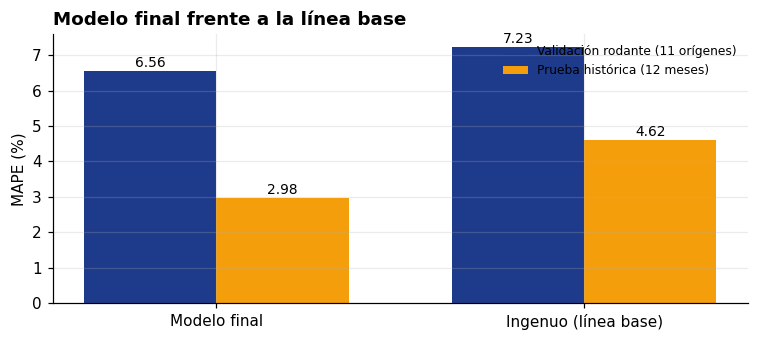

In [19]:
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(2); w = .36
v1 = comparacion["MAPE validación, 11 orígenes (%)"].values; v2 = comparacion["MAPE prueba histórica (%)"].values
ax.bar(x - w/2, v1, w, color="#1E3A8A", label="Validación rodante (11 orígenes)")
ax.bar(x + w/2, v2, w, color=COL["test"], label="Prueba histórica (12 meses)")
for i in range(2):
    ax.text(x[i] - w/2, v1[i] + .1, f"{v1[i]:.2f}", ha="center", fontsize=9)
    ax.text(x[i] + w/2, v2[i] + .1, f"{v2[i]:.2f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(["Modelo final", "Ingenuo (línea base)"]); ax.set_ylabel("MAPE (%)")
ax.set_title("Modelo final frente a la línea base", loc="left", fontweight="bold"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(f"{CARPETA}/figuras/fig3_ingenuo.png", dpi=200); plt.show()

## 10. Pronóstico futuro a 12 meses
El modelo final se **reentrena con toda la serie** y genera 12 pronósticos independientes de la prueba histórica.

**Banda del 80 %.** Con los errores relativos de la validación rodante, $e_h=\dfrac{\text{IPAP}_{T+h}}{\widehat{\text{IPAP}}_{T+h}}-1$, se toman los percentiles 10 y 90 de cada horizonte:
$$\Big[\;\widehat{\text{IPAP}}_{T+h}\,(1+e_h^{P10}),\;\;\widehat{\text{IPAP}}_{T+h}\,(1+e_h^{P90})\;\Big]$$

In [20]:
P_FUT     = modelo_final(y, H)
pred_fut  = P_FUT["MODELO FINAL"]
meses_fut = pd.period_range(y.index[-1] + 1, periods=H, freq="M")
tabla_futuro = pd.DataFrame({"Mes": meses_fut.astype(str), "Pronóstico IPAP": pred_fut.round(2),
                             "Límite inferior 80 %": (pred_fut * (1 + P10)).round(2),
                             "Límite superior 80 %": (pred_fut * (1 + P90)).round(2)})
assert MES_OBJETIVO in tabla_futuro["Mes"].values, "El pronóstico no cubre el mes objetivo"
i = list(tabla_futuro["Mes"]).index(MES_OBJETIVO); OCT = tabla_futuro.iloc[i]
display(tabla_futuro)
print(f"\nPronóstico {MES_OBJETIVO}: {OCT['Pronóstico IPAP']:.2f}  (banda 80 %: {OCT['Límite inferior 80 %']:.2f} – {OCT['Límite superior 80 %']:.2f})")
print(f"Aporte de cada componente en {MES_OBJETIVO}:", {k: round(float(P_FUT[k][i]), 2) for k in ["ARIMA","Estacional","Telaraña","Bottom-up"]})

,Mes,Pronóstico IPAP,Límite inferior 80 %,Límite superior 80 %
0,2026-08,251.09,245.77,256.94
1,2026-09,251.90,243.44,262.85
2,2026-10,252.93,240.95,272.44
3,2026-11,253.36,239.14,287.14
4,2026-12,255.00,242.70,288.20
5,2027-01,256.78,240.95,288.91
6,2027-02,258.80,240.85,294.63
7,2027-03,259.90,245.73,302.01
8,2027-04,261.52,248.14,312.10
9,2027-05,262.42,246.75,322.03



Pronóstico 2026-10: 252.93  (banda 80 %: 240.95 – 272.44)
Aporte de cada componente en 2026-10: {'ARIMA': 255.39, 'Estacional': 246.31, 'Telaraña': 257.77, 'Bottom-up': 252.26}


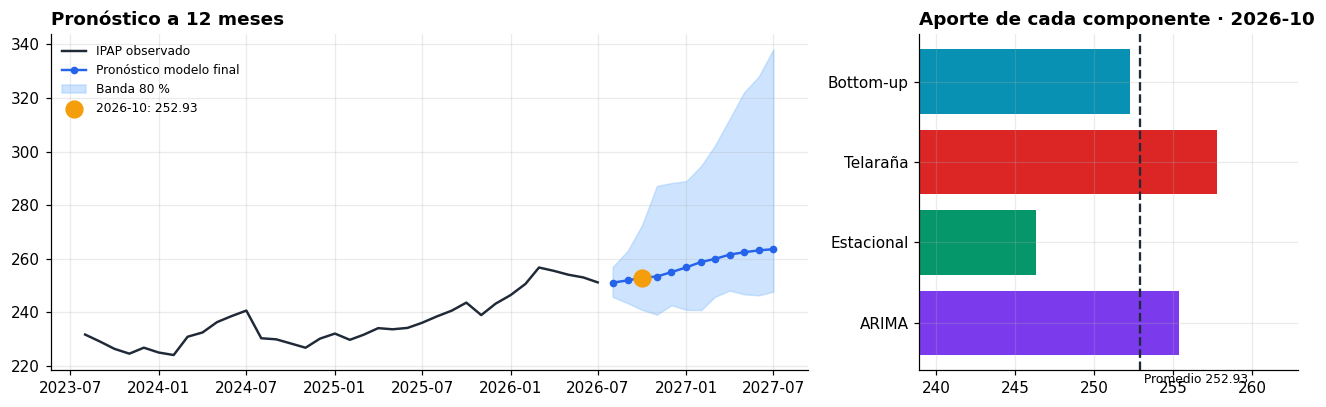

In [21]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2, 1]})
hist = y.iloc[-36:]; ff = meses_fut.to_timestamp()
a1.plot(hist.index.to_timestamp(), hist.values, color=COL["real"], lw=1.6, label="IPAP observado")
a1.plot(ff, pred_fut, "o-", color=COL["pred"], ms=4, lw=1.6, label="Pronóstico modelo final")
a1.fill_between(ff, tabla_futuro["Límite inferior 80 %"], tabla_futuro["Límite superior 80 %"], color=COL["banda"], alpha=.45, label="Banda 80 %")
a1.scatter(ff[i], pred_fut[i], s=120, color=COL["test"], zorder=5, label=f"{MES_OBJETIVO}: {pred_fut[i]:.2f}")
a1.set_title("Pronóstico a 12 meses", loc="left", fontweight="bold"); a1.legend(frameon=False, fontsize=8, loc="upper left")
ap = {k: P_FUT[k][i] for k in ["ARIMA", "Estacional", "Telaraña", "Bottom-up"]}
a2.barh(list(ap), list(ap.values()), color=[COL[k] for k in ap])
a2.axvline(pred_fut[i], color=COL["real"], ls="--"); a2.text(pred_fut[i], -0.75, f" Promedio {pred_fut[i]:.2f}", fontsize=8)
a2.set_xlim(min(ap.values()) * 0.97, max(ap.values()) * 1.02)
a2.set_title(f"Aporte de cada componente · {MES_OBJETIVO}", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{CARPETA}/figuras/fig4_pronostico.png", dpi=200); plt.show()

## 11. Exportar resultados

In [22]:
with pd.ExcelWriter(f"{CARPETA}/Resultados_IPAP_RetoB.xlsx") as w:
    tabla_prueba.to_excel(w, sheet_name="Prueba_historica", index=False)
    tabla_futuro.to_excel(w, sheet_name="Pronostico_futuro", index=False)
    comparacion.to_excel(w, sheet_name="Comparacion_ingenuo")
    diag.to_excel(w, sheet_name="Diagnostico"); sens.to_excel(w, sheet_name="Sensibilidad")
    m_tr.round(5).to_frame("indice_mediano").to_excel(w, sheet_name="Indice_transacciones")
tabla_prueba.to_csv(f"{CARPETA}/prueba_historica.csv", index=False)
tabla_futuro.to_csv(f"{CARPETA}/pronostico_futuro.csv", index=False)

print("RESUMEN")
print(f"  Datos:              IPAP {y.index[0]}–{y.index[-1]} ({len(y)} meses) + transacciones BMC")
print(f"  MAPE prueba:        {MAPE_FINAL:.2f} %  →  {nota(MAPE_FINAL)}   (ingenuo: {MAPE_ING:.2f} %)")
print(f"  Pronóstico {MES_OBJETIVO}: {OCT['Pronóstico IPAP']:.2f}")
print(f"  Archivos en ./{CARPETA}/")

RESUMEN
  Datos:              IPAP 2012-01–2026-07 (175 meses) + transacciones BMC
  MAPE prueba:        2.98 %  →  10 · Excelente   (ingenuo: 4.62 %)
  Pronóstico 2026-10: 252.93
  Archivos en ./outputs/
